# 14 — The final model: one skeleton LSTM for the demo

Notebook 13b chose the **skeleton LSTM**: first or second in every test, also on datasets it had never seen (0.82 to 0.90 video accuracy), small and fast. In this notebook we build **the model of the demo**:

1. train it on **all** our side-camera videos: URFD camera 0, GMDCSA-24 and CAUCAFall (**330 videos**);
2. choose its **threshold** with people **not used in training** (5 folds by person, as in 13b);
3. **save** it in `models/fall_lstm.pt`;
4. check that the demo program **`scripts/detect.py`**, which starts from the raw video, gives the same answer as this notebook.

The ceiling camera (URFD camera 1) is **not** used to train: it has only falls, no daily activities, so the model could learn *"seen from above = fall"*.

The windows, the model, the smoothing and the alarm are **imported from `scripts/detect.py`**: the demo cannot do something different from what we test here.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"                # needed for repeatable results on the GPU
import sys, time
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
sys.path.insert(0, str(Path("..") / "scripts"))
import detect as D                                               # the demo program: same windows, model, smoothing and alarm

RAW, PROC = Path("..") / "data" / "raw", Path("..") / "data" / "processed"
NEW, FINAL = PROC / "new", PROC / "final"; FINAL.mkdir(exist_ok=True)
torch.use_deterministic_algorithms(True); torch.backends.cudnn.benchmark = False
device = "cuda" if torch.cuda.is_available() else "cpu"

frames, videos = pd.read_csv(NEW / "frames.csv"), pd.read_csv(NEW / "videos.csv")        # notebook 13a
info = videos.set_index("video", drop=False)
y, fold, dataset = frames.answer.to_numpy(copy=True), frames.fold.to_numpy(), frames.dataset.to_numpy()
ROWS = {v: np.sort(i) for v, i in frames.groupby("video").indices.items()}
TRAIN_SETS = ["URFD cam0", "GMDCSA-24", "CAUCAFall"]

WINDOWS = np.zeros((len(frames), D.T, 13, 5), np.float32)                                # 1.5 s of skeleton for every image, with the code of the demo
for v, idx in ROWS.items():
    WINDOWS[idx] = D.windows_of(np.load(NEW / "skeletons" / f"{v}.npy"), frames["index"].to_numpy()[idx], info.fps[v], frames.width[idx[0]] / 480)
WINDOWS = torch.from_numpy(WINDOWS).to(device)

used = videos[videos.dataset.isin(TRAIN_SETS)]
table = used.groupby("dataset").agg(videos=("video", "size"), falls=("kind", lambda k: (k == "fall").sum()), ADLs=("kind", lambda k: (k == "adl").sum()), people=("person", "nunique"))
table["images with an answer"] = pd.Series(dataset[y >= 0]).value_counts(); table["of which fall"] = pd.Series(dataset[y == 1]).value_counts()
print(torch.cuda.get_device_name(0) if device == "cuda" else "CPU", "| windows:", tuple(WINDOWS.shape))
table.loc[TRAIN_SETS]

NVIDIA GeForce RTX 4050 Laptop GPU | windows: (27941, 15, 13, 5)


,videos,falls,ADLs,people,images with an answer,of which fall
dataset,,,,,,
URFD cam0,70,30,40,5,3775,378
GMDCSA-24,160,79,81,4,10373,1206
CAUCAFall,100,50,50,10,6939,768


💡 **Interpretation:** **330 videos** to learn from (159 falls, 171 ADLs, 19 people) and 21,087 images with an answer, of which 2,352 *fall*. GMDCSA gives almost half of them (10,373).

## Step 1 — The training, exactly as in 13b

Same training images (all the *fall* images, 1 *no fall* image out of 2), same mirror / size / noise changes, **20 epochs**, same settings. To be sure that nothing changed, we train again **one LSTM of 13b** (learned on URFD, random start 0) and compare its scores with the ones saved by 13b.

In [2]:
FLIP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11]                                       # left <-> right
def window_batch(b, train):
    w = WINDOWS[b].clone()
    if train:                                                                             # mirror, size, small noise (notebook 12)
        f = torch.rand(len(w), device=device) < 0.5
        w[f] = w[f][:, :, FLIP] * torch.tensor([-1, 1, -1, 1, 1.0], device=device)
        w[..., :4] *= torch.empty(len(w), 1, 1, 1, device=device).uniform_(0.9, 1.1); w[..., :2] += 0.02 * torch.randn_like(w[..., :2])
    return w

def train_rows(mask):                                                                     # all the fall images, 1 no-fall image out of 2
    idx = np.flatnonzero(mask & (y >= 0)); keep = np.ones(len(idx), bool)
    zero = np.flatnonzero(y[idx] == 0); keep[zero[1::2]] = False
    return idx[keep]

def train_lstm(rows, seed, epochs=20):
    torch.manual_seed(seed); net = D.LSTM(2).to(device)
    Y = torch.from_numpy(y).to(device); rows = torch.from_numpy(rows).to(device)
    weight = 1 / torch.bincount(Y[rows], minlength=2).float()
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-2)
    for _ in range(epochs):
        net.train()
        for b in torch.split(rows[torch.randperm(len(rows), device=device)], 128):
            if len(b) < 2: continue
            loss = nn.functional.cross_entropy(net(window_batch(b, True)), Y[b], weight=weight / weight.mean())
            opt.zero_grad(); loss.backward(); opt.step()
    return net.eval()

def scores_of(net, rows):
    with torch.no_grad():
        return torch.cat([net(window_batch(b, False)).softmax(1)[:, 1] for b in torch.split(torch.from_numpy(rows).to(device), 512)]).cpu().numpy()

urfd = dataset == "URFD cam0"
t = time.time(); again = scores_of(train_lstm(train_rows(urfd), 0), np.flatnonzero(~urfd))
saved = np.load(PROC / "cross" / "SkeletonLSTM_URFD_0.npy")[~urfd]
print(f"one LSTM trained in {time.time() - t:.0f} s | {len(again):,} scores | largest difference with notebook 13b: {np.abs(again - saved).max():.1e}")

one LSTM trained in 6 s | 23,937 scores | largest difference with notebook 13b: 8.8e-08


💡 **Interpretation:** trained again, the LSTM gives **the same scores as in 13b** (largest difference 0.00000009, a rounding of the GPU): the training here is exactly the one we tested.
One LSTM takes only a few seconds to train (6 s).

## Step 2 — Choose the threshold with people not used in training

1. **5 folds by person** over the 3 datasets (the folds of 13a: a person, or a room shared by two people, is in one fold only). Train on 4 folds, score the 5th.
2. Each time **3 LSTMs** (3 random starts), and we take the **mean** of their scores: one LSTM alone changed a lot with its random start in 13b (80 to 88% on GMDCSA). The final model will also be the mean of 3.
3. The threshold is the one with the most *(falls caught in time − ADL videos with a false alarm − falls with an early alarm)* over the 330 videos, as in 13b.

0.0 min (0 if loaded from the saved file)
threshold: 0.989 (3 thresholds with the best points: 129)


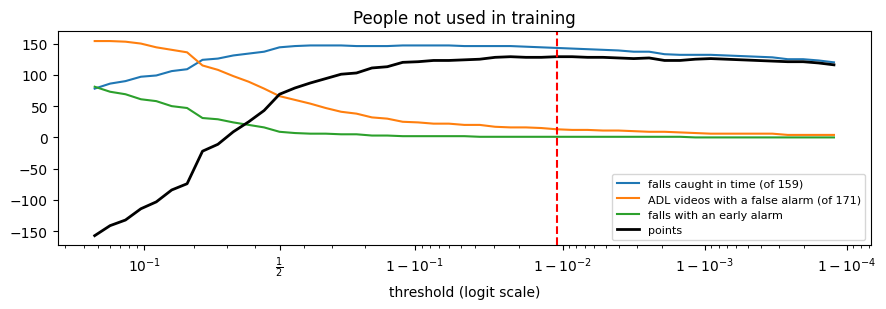

In [3]:
SEEDS = range(3)
inside = np.isin(dataset, TRAIN_SETS)
file = FINAL / "lstm_new_people.npy"
t = time.time()
if file.exists(): oof = np.load(file)
else:
    oof = np.zeros(len(frames), np.float32)
    for k in range(1, 6):
        test, rows = np.flatnonzero(inside & (fold == k)), train_rows(inside & (fold != k))
        oof[test] = np.mean([scores_of(train_lstm(rows, s), test) for s in SEEDS], 0)
    np.save(file, oof)
print(f"{(time.time() - t) / 60:.1f} min (0 if loaded from the saved file)")

THRESHOLDS = 1 / (1 + np.exp(-np.arange(-3, 9.01, 0.25)))                                # the 49 thresholds of 13b
TIMES, START, KIND = frames.t.to_numpy(), info.start.to_dict(), info.kind.to_dict()
names = list(used.video)

def result_of(v, s, thr):
    """s = smoothed score of video v. One line: alarm, first alarm, in time, early (aligned start of 13a)."""
    a = D.alarm_times(s, TIMES[ROWS[v]], thr); fall = KIND[v] == "fall"; first = a[0] if len(a) else np.nan
    return {"video": v, "dataset": info.dataset[v], "fall": fall, "alarm": len(a) > 0, "first": first,
            "in time": fall and len(a) > 0 and START[v] - 1e-9 <= first <= START[v] + 3, "early": fall and len(a) > 0 and first < START[v] - 1e-9}
def point(r): return int(r["in time"]) - int(r["early"]) - int(r["alarm"] and not r["fall"])

SMOOTH = {v: D.smooth(oof[ROWS[v]]) for v in names}
grid = pd.DataFrame([{"threshold": thr, **pd.DataFrame([result_of(v, SMOOTH[v], thr) for v in names]).assign(fa=lambda r: r.alarm & ~r.fall)[["in time", "early", "fa"]].sum()} for thr in THRESHOLDS])
grid["points"] = grid["in time"] - grid.early - grid.fa
best = np.flatnonzero(grid.points == grid.points.max()); THRESHOLD = float(THRESHOLDS[best[len(best) // 2]])  # the middle one if several
print(f"threshold: {THRESHOLD:.3f} ({len(best)} thresholds with the best points: {grid.points.max()})")

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(grid.threshold, grid["in time"], label="falls caught in time (of 159)"); ax.plot(grid.threshold, grid.fa, label="ADL videos with a false alarm (of 171)")
ax.plot(grid.threshold, grid.early, label="falls with an early alarm"); ax.plot(grid.threshold, grid.points, "k", lw=2, label="points")
ax.axvline(THRESHOLD, color="red", ls="--"); ax.set_xscale("logit"); ax.set_xlabel("threshold (logit scale)"); ax.legend(fontsize=8); ax.set_title("People not used in training")
plt.tight_layout(); plt.show()

💡 **Interpretation:** the most points (129) come with a **high threshold**: 3 thresholds are equal and we take the middle one, **0.989**. At 0.5 a few more falls are caught, but about 65 ADL videos get a false alarm (orange).
During a fall the scores of the LSTM are very close to 1, so a high threshold loses few falls.

In [4]:
res = pd.DataFrame([result_of(v, SMOOTH[v], THRESHOLD) for v in names])
def marks(r):
    falls, adls = r[r.fall], r[~r.fall]
    lat = (falls["first"] - falls.video.map(START))[falls["in time"].astype(bool)]
    return pd.Series({"videos": len(r), "video accuracy": (r.alarm == r.fall).mean(), "falls in time": f"{falls['in time'].sum()} of {len(falls)}",
                      "ADLs with a false alarm": f"{adls.alarm.sum()} of {len(adls)}", "early alarms": falls.early.sum(), "latency (s, median)": lat.median()})
mk = pd.DataFrame({**{d: marks(res[res.dataset == d]) for d in TRAIN_SETS}, "all 3": marks(res)}).T
print("false alarms by activity:", res[~res.fall & res.alarm].video.map(info.activity).value_counts().to_dict())
mk.round(2)

false alarms by activity: {'adl': 3, 'Sitting + Sleeping': 2, 'Exercising + Standing': 2, 'Sleeping + Standing': 1, 'Reading + Sitting + Standing': 1, 'Sitting + Walking + Writing': 1, 'Drinking + Sitting + Standing': 1, 'Exercising + Sitting': 1, 'Kneel': 1}


,videos,video accuracy,falls in time,ADLs with a false alarm,early alarms,"latency (s, median)"
URFD cam0,70,0.957143,30 of 30,3 of 40,0,0.683333
GMDCSA-24,160,0.90625,70 of 79,9 of 81,1,1.005228
CAUCAFall,100,0.92,43 of 50,1 of 50,0,0.85
all 3,330,0.921212,143 of 159,13 of 171,1,0.896915


💡 **Interpretation:** with people **not used in training**, the final recipe gets **0.92** of the videos right: 143 of 159 falls in time, 13 of 171 ADLs with a false alarm, 1 early alarm, alarm 0.9 s after the start (median). Close to 13b with new people (0.96 URFD, 0.91 GMDCSA, 0.94 CAUCAFall).
The false alarms come again from **sleeping** (3) and **exercising** (3). These rooms were seen in training: in a new home expect less (0.82 to 0.88 in test B).

## Step 3 — The final model: 3 LSTMs on all the 330 videos

Same training on **all** the images of the 3 datasets, 3 random starts. We save the 3 networks and the threshold in **`models/fall_lstm.pt`**, then load the file **the way the demo does** (on the processor, not the graphics card) and compare.

In [5]:
rows = train_rows(inside)
t = time.time(); nets = [train_lstm(rows, s) for s in SEEDS]
torch.save({"nets": [{k: w.cpu() for k, w in n.state_dict().items()} for n in nets], "threshold": THRESHOLD, "trained on": TRAIN_SETS,
            "videos": len(names), "training images": len(rows), "window": "15 images, 10 per second (1.5 s)", "made by": "notebooks/14_final_model.ipynb"}, D.FALL_MODEL)
print(f"3 LSTMs trained on {len(rows):,} images in {time.time() - t:.0f} s | saved: {D.FALL_MODEL.name}, {D.FALL_MODEL.stat().st_size / 1e6:.2f} MB")

model = D.FallModel()                                                                     # exactly what the demo loads
some = np.flatnonzero(inside)
gpu = np.mean([scores_of(n, some) for n in nets], 0); cpu = model.scores(WINDOWS[torch.from_numpy(some).to(device)].cpu().numpy())
print(f"threshold in the file: {model.threshold:.3f} | largest difference between the notebook (GPU) and the demo (CPU): {np.abs(gpu - cpu).max():.1e}")

3 LSTMs trained on 11,720 images in 23 s | saved: fall_lstm.pt, 0.37 MB
threshold in the file: 0.989 | largest difference between the notebook (GPU) and the demo (CPU): 2.0e-03


💡 **Interpretation:** the 3 LSTMs learn in about 25 s and the file is only **0.37 MB**. Loaded like the demo (on the processor), the scores differ by at most 0.002 from the GPU.
That can change an alarm only when a score is just at the threshold.

## Step 4 — Does the demo program give the same answer, from the raw video?

`scripts/detect.py` does everything again from the **video file** (or the folder of images): reads it, runs MediaPipe, builds the windows, gives the scores and the alarm. We compare with what this notebook has, for 2 GMDCSA videos (mp4) and 2 CAUCAFall videos (images).

These videos were used to train the final model, so this is **not a test** of the model: it only checks that **the program is the same**.

In [6]:
check = ["gmd-s1-fall-11", "gmd-s2-adl-05", "cau-s01-fall-left", "cau-s04-kneel"]
RES, rows = {}, []
t = time.time()
for v in check:
    r = RES[v] = D.analyse(RAW / info.path[v], model, fps=info.fps[v])
    old = np.load(NEW / "skeletons" / f"{v}.npy"); same = len(old) == len(r["skeletons"])
    here = model.scores(WINDOWS[torch.from_numpy(ROWS[v]).to(device)].cpu().numpy())
    rows.append({"video": v, "kind": KIND[v], "images": len(r["skeletons"]), "same number of images": same,
                 "same images with a person": same and np.array_equal(np.isnan(old[:, 0, 0]), np.isnan(r["skeletons"][:, 0, 0])),
                 "largest joint difference": np.nanmax(np.abs(old - r["skeletons"])) if same else np.nan,
                 "largest score difference": np.abs(here - r["score"]).max() if same else np.nan, "demo says": D.sentence(r).split("  ")[0]})
print(f"{(time.time() - t) / len(check):.1f} s per video (MediaPipe on every image)")
pd.DataFrame(rows).set_index("video")

11.7 s per video (MediaPipe on every image)


,kind,images,same number of images,same images with a person,largest joint difference,largest score difference,demo says
video,,,,,,,
gmd-s1-fall-11,fall,181,True,True,0.0,0.0,FALL detected at 1.4 s
gmd-s2-adl-05,adl,323,True,True,0.0,0.0,NO FALL
cau-s01-fall-left,fall,87,True,True,0.0,0.0,FALL detected at 1.5 s
cau-s04-kneel,adl,223,True,True,0.0,0.0,NO FALL


💡 **Interpretation:** starting from the raw files, the demo finds **the same skeletons and the same scores** (difference 0) and the right answer for the 4 videos: the program is the one we tested.
It needs about 9 s per video, a little longer than the videos themselves (8 s on average): MediaPipe looks at every image.

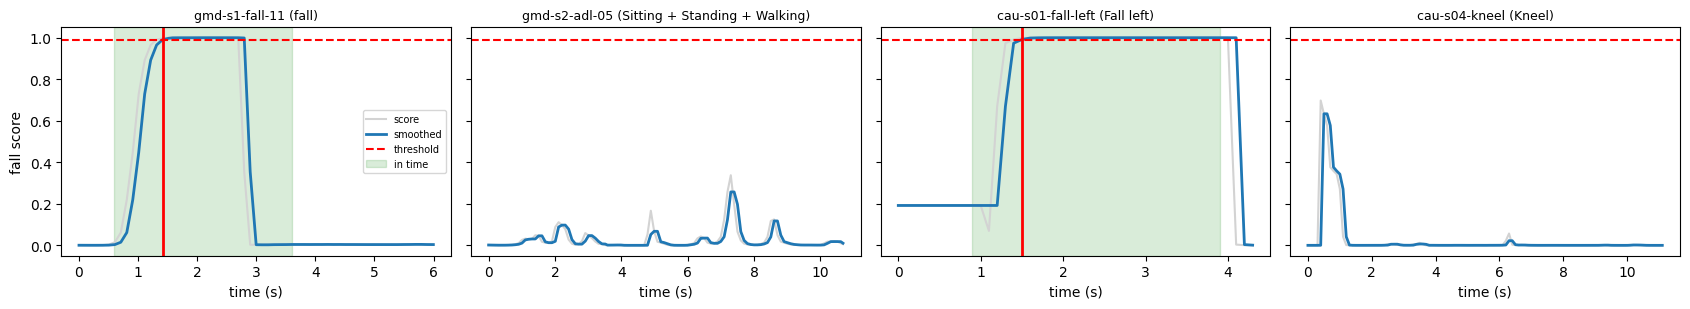

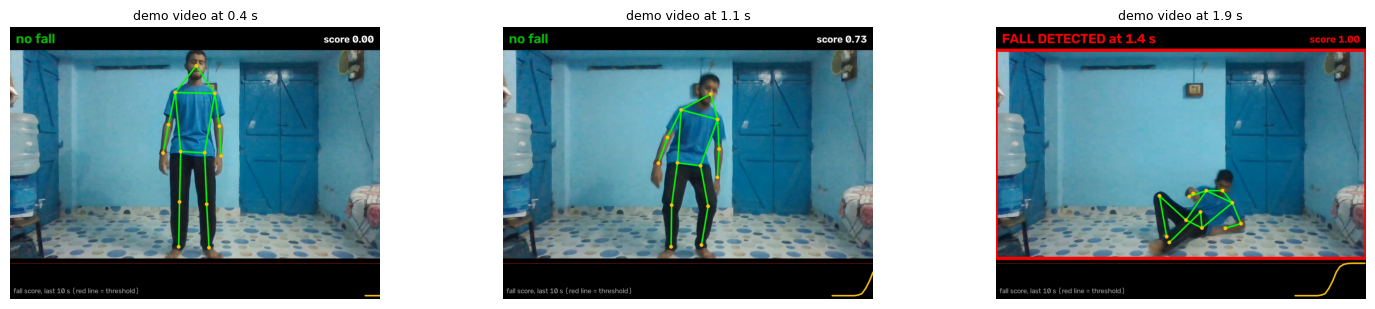

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.2), sharey=True)
for ax, v in zip(axes, check):
    r = RES[v]
    ax.plot(r["t"], r["score"], color="lightgrey", label="score"); ax.plot(r["t"], r["smooth"], lw=2, label="smoothed")
    ax.axhline(model.threshold, color="red", ls="--", label="threshold")
    if KIND[v] == "fall": ax.axvspan(START[v], START[v] + 3, color="green", alpha=0.15, label="in time")
    for a in r["alarms"][:1]: ax.axvline(a, color="red", lw=2)
    ax.set_title(f"{v} ({info.activity[v]})", fontsize=9); ax.set_xlabel("time (s)")
axes[0].set_ylabel("fall score"); axes[0].legend(fontsize=7); plt.tight_layout(); plt.show()

D.OUT.mkdir(parents=True, exist_ok=True); D.save_video(RES["gmd-s1-fall-11"], D.OUT / "gmd-s1-fall-11_result.mp4")    # the video of the demo
cap = cv2.VideoCapture(str(D.OUT / "gmd-s1-fall-11_result.mp4")); fps = cap.get(cv2.CAP_PROP_FPS); a = RES["gmd-s1-fall-11"]["alarms"]; first = a[0] if len(a) else START["gmd-s1-fall-11"] + 1
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, tt in zip(axes, [first - 1.0, first - 0.3, first + 0.5]):
    cap.set(cv2.CAP_PROP_POS_FRAMES, round(tt * fps)); ok, im = cap.read()
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(f"demo video at {tt:.1f} s", fontsize=9)
plt.tight_layout(); plt.show()

💡 **Interpretation:** in the falls the score goes from 0 to 1 in less than 1 s, and the alarm comes 0.8 s (GMDCSA) and 0.6 s (CAUCAFall) after the start; in the ADLs it stays far below the threshold (about 0.3, and 0.6 when kneeling).
The demo video: *no fall* in green with the skeleton on the person, then **FALL DETECTED** in red with a red frame; the score of the last 10 s is under the image.

## What we learned

1. **The final model** is the mean of **3 skeleton LSTMs**, trained on the 330 side-camera videos of URFD, GMDCSA-24 and CAUCAFall, with the threshold **0.989**. It is one file of **0.37 MB** (`models/fall_lstm.pt`), plus MediaPipe (9.4 MB).
2. **With people not used in training** it gets **0.92** of the videos right: 143 of 159 falls caught in time, 13 of 171 daily activities with a false alarm, alarm 0.9 s after the start of the fall (median).
3. **The demo program `scripts/detect.py`** gives exactly the same skeletons and scores as this notebook, from the raw video, in about the time of the video on this laptop.
4. **What to expect in a new home:** less than 0.92, because these people were filmed in rooms the model knows. Test B of 13b, with a dataset never seen, gave 0.82 to 0.88.

**Limits:** the threshold was chosen on these 3 datasets; lying on a bed, sleeping and exercising still give false alarms; the ceiling camera was not used; the 4 videos of Step 4 were used in training, so they only check the program, not the model. The real test is **new videos filmed at home** (next notebook).